In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
pd.unique(df['gender'])

array(['Female', 'Male'], dtype=object)

In [13]:
df['Churn'].value_counts().reset_index()

,Churn,count
0,No,5174
1,Yes,1869


In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'] , errors = 'coerce')

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


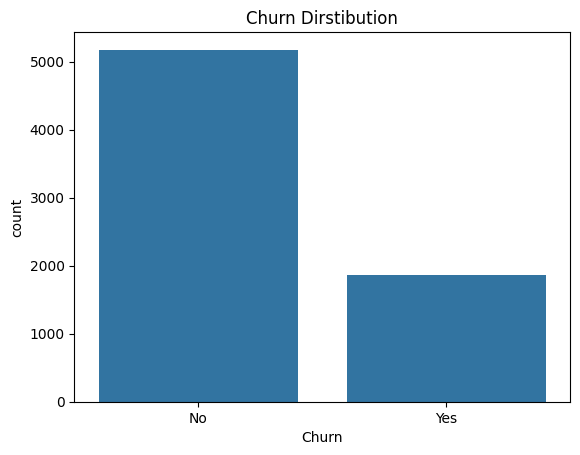

In [15]:
print(df['Churn'].value_counts(normalize= True).round(3))
sns.countplot(x = 'Churn' , data = df)
plt.title('Churn Dirstibution')
plt.show()

In [16]:
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)
    print(f"\nChurn rate by {col}:\n{rate}")


Churn rate by Contract:
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

Churn rate by InternetService:
InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64

Churn rate by PaymentMethod:
PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn, dtype: float64

Churn rate by TechSupport:
TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, dtype: float64


In [17]:
#preprocessing and train test split
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [18]:
df = df.drop(columns=["customerID"])

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

x = df.drop(columns=['Churn'])
y = df['Churn']

print(x)

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL             No          Yes   
1      

In [19]:
print(y)


0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64


In [20]:
# Split columns by type
num_col = ["tenure","MonthlyCharges","TotalCharges"]
cat_col = [c for c in x.columns if c not in num_col]

# Preprocessor: scale numbers, one-hot encode categories
preprocessor = ColumnTransformer([
    ("num" , StandardScaler() , num_col),
    ("cat" , OneHotEncoder(handle_unknown='ignore') , cat_col)
])

In [21]:
x_train , x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y, random_state=42)
x.shape,x_train.shape,x_test.shape

((7043, 19), (5634, 19), (1409, 19))

In [22]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Ensure TotalCharges is numeric and clean in x_train and x_test
for dataset in [x_train, x_test]:
    dataset["TotalCharges"] = pd.to_numeric(dataset["TotalCharges"], errors='coerce')
    dataset["TotalCharges"] = dataset["TotalCharges"].fillna(0)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = {}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    scores = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

print(pd.DataFrame(results).T.round(3))

                     accuracy  precision  recall     f1  roc_auc
Logistic Regression     0.802      0.652   0.544  0.592    0.846
Random Forest           0.786      0.628   0.482  0.545    0.820
XGBoost                 0.784      0.612   0.515  0.559    0.825


In [23]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"}

# --- Logistic Regression ---
lr_pipe = Pipeline([("preprocessor", preprocessor),
                    ("model", LogisticRegression(max_iter=2000, random_state=42))])

lr_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}
lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring=scoring,
                         refit="roc_auc", n_jobs=-1)
lr_search.fit(x_train, y_train)

# --- XGBoost ---
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
xgb_pipe = Pipeline([("preprocessor", preprocessor),
                     ("model", XGBClassifier(eval_metric="logloss", random_state=42))])

xgb_params = {
    "model__n_estimators": [100, 200, 400],
    "model__max_depth": [2, 3, 4, 6],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.7, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.9, 1.0],
    "model__scale_pos_weight": [1, neg / pos],
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_params, n_iter=30, cv=cv,
                                scoring=scoring, refit="roc_auc",
                                n_jobs=-1, random_state=42)
xgb_search.fit(x_train, y_train)

# Compare best results
for name, s in [("Logistic Regression", lr_search), ("XGBoost", xgb_search)]:
    i = s.best_index_
    print(name, s.best_params_)
    print({m: round(s.cv_results_[f"mean_test_{m}"][i], 3) for m in scoring})

Logistic Regression {'model__C': 10, 'model__class_weight': None}
{'roc_auc': np.float64(0.846), 'f1': np.float64(0.597), 'recall': np.float64(0.549)}
XGBoost {'model__subsample': 0.9, 'model__scale_pos_weight': 1, 'model__n_estimators': 400, 'model__max_depth': 3, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.7}
{'roc_auc': np.float64(0.85), 'f1': np.float64(0.579), 'recall': np.float64(0.502)}



=== Logistic Regression | Test ROC-AUC: 0.841 ===
              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409


=== LR (balanced) | Test ROC-AUC: 0.841 ===
              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


=== XGBoost (tuned) | Test ROC-AUC: 0.848 ===
              precision    recall  f1-score   support

    No churn       0.84      0.91      0.87      1035
       Churn       0.68      0.51      0.59       374

    accuracy                           

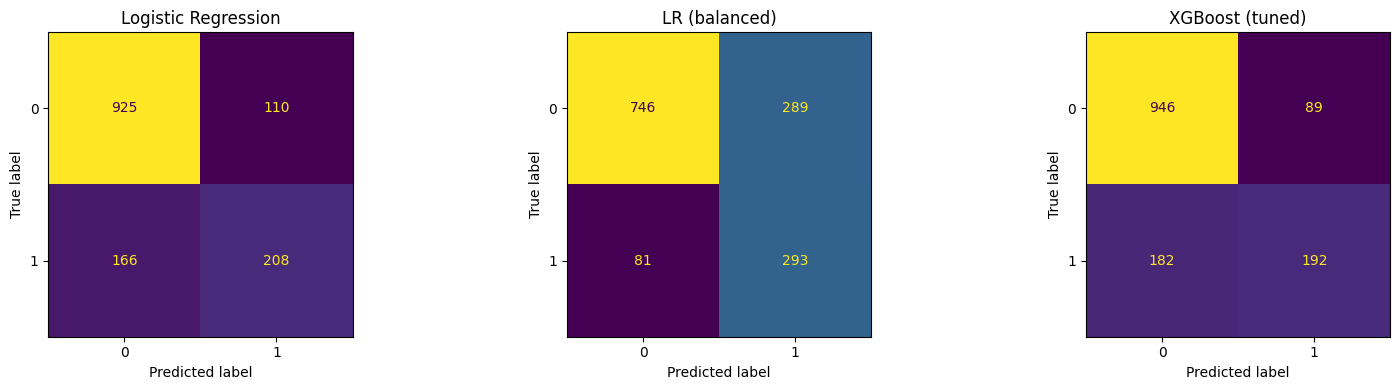

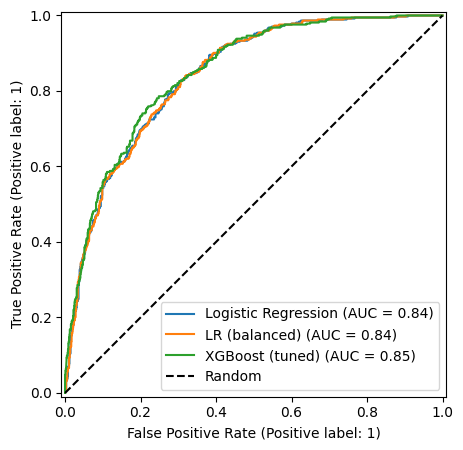

In [24]:
from sklearn.base import clone
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)
import matplotlib.pyplot as plt

lr_best = lr_search.best_estimator_
xgb_best = xgb_search.best_estimator_
lr_bal = clone(lr_best).set_params(model__class_weight="balanced")
lr_bal.fit(x_train, y_train)

final_models = {
    "Logistic Regression": lr_best,
    "LR (balanced)": lr_bal,
    "XGBoost (tuned)": xgb_best,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, final_models.items()):
    proba = m.predict_proba(x_test)[:, 1]
    pred = m.predict(x_test)
    print(f"\n=== {name} | Test ROC-AUC: {roc_auc_score(y_test, proba):.3f} ===")
    print(classification_report(y_test, pred, target_names=["No churn", "Churn"]))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ROC curves on one plot
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in final_models.items():
    RocCurveDisplay.from_estimator(m, x_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.legend()
plt.show()

                                  feature      coef  odds_ratio
                      num__MonthlyCharges -2.006558        0.13
         cat__InternetService_Fiber optic  1.319554        3.74
                              num__tenure -1.307710        0.27
                 cat__InternetService_DSL -1.137704        0.32
                   cat__Contract_Two year -0.813822        0.44
  cat__OnlineSecurity_No internet service -0.585160        0.56
                  cat__InternetService_No -0.585160        0.56
    cat__OnlineBackup_No internet service -0.585160        0.56
     cat__TechSupport_No internet service -0.585160        0.56
cat__DeviceProtection_No internet service -0.585160        0.56


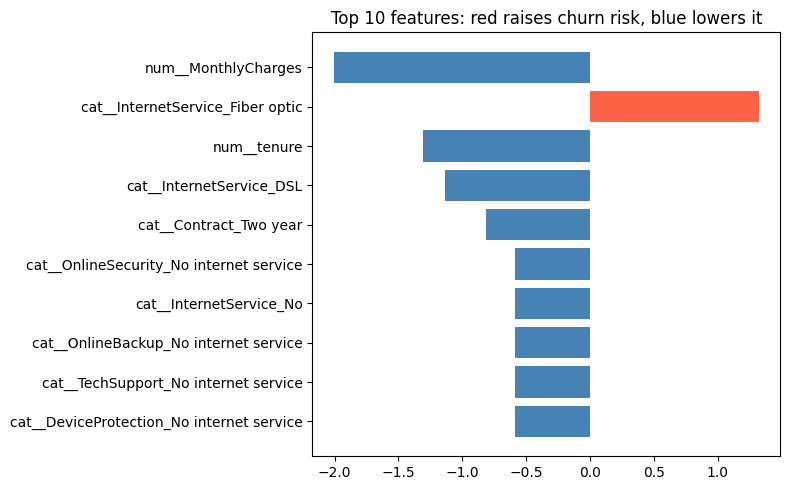


Permutation importance (drop in ROC-AUC when shuffled):
tenure             0.1779
MonthlyCharges     0.1219
InternetService    0.1213
Contract           0.0344
StreamingMovies    0.0201
StreamingTV        0.0195
TotalCharges       0.0165
MultipleLines      0.0088
dtype: float64


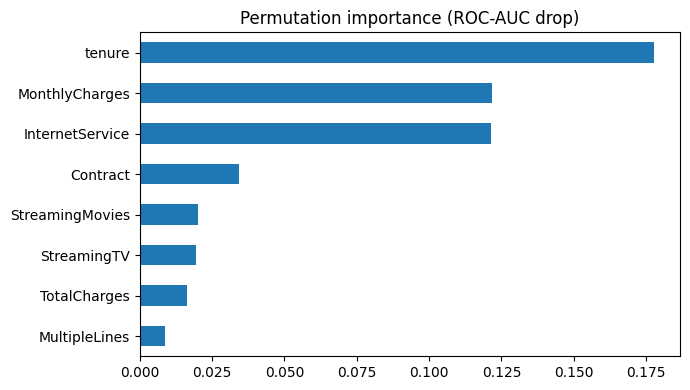

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# --- Method 1: Logistic Regression coefficients ---
feature_names = lr_best.named_steps["preprocessor"].get_feature_names_out()
coefs = lr_best.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({"feature": feature_names, "coef": coefs})
coef_df["odds_ratio"] = np.exp(coef_df["coef"]).round(2)
coef_df = coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index)

print(coef_df.head(10).to_string(index=False))

top = coef_df.head(10).iloc[::-1]
colors = ["tomato" if c > 0 else "steelblue" for c in top["coef"]]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coef"], color=colors)
plt.title("Top 10 features: red raises churn risk, blue lowers it")
plt.tight_layout()
plt.show()

# --- Method 2: Permutation importance on the test set (original columns) ---
perm = permutation_importance(lr_best, x_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=42, n_jobs=-1)
perm_df = (pd.Series(perm.importances_mean, index=x_test.columns)
           .sort_values(ascending=False))
print("\nPermutation importance (drop in ROC-AUC when shuffled):")
print(perm_df.head(8).round(4))

perm_df.head(8).iloc[::-1].plot(kind="barh", figsize=(7, 4),
                                title="Permutation importance (ROC-AUC drop)")
plt.tight_layout()
plt.show()